# FER2013 Facial Emotion Recognition with DeepFace-Compatible Training

This notebook develops a facial-expression recognition model for the FER2013 dataset, aimed at future integration with a live camera pipeline for an emotion-aware receptionist robot.

The notebook clearly separates three different ideas:

1. Using the DeepFace framework for preprocessing, face detection, and alignment.
2. Using a custom FER2013-trained model for emotion classification.
3. Using the trained model in a DeepFace-compatible inference workflow.

DeepFace is a framework for face analysis and detection; it does not expose a direct, reliable FER2013 fine-tuning API in the same way as a standard Keras training pipeline. For this reason, the notebook uses DeepFace appropriately for face-related preprocessing and compares it with a custom FER2013-trained classifier built on a face-recognition backbone.

## 1. Environment setup

Install or verify the required packages and confirm the runtime environment.

In [22]:
import importlib
import sys

REQUIRED_PACKAGES = [
    'numpy',
    'pandas',
    'matplotlib',
    'seaborn',
    'cv2',
    'sklearn',
    'tensorflow',
    'deepface',
    'keras',
]

missing = []
for package in REQUIRED_PACKAGES:
    try:
        importlib.import_module(package)
    except ImportError:
        missing.append(package)

if missing:
    print(f'Missing packages: {missing}')
    print('Install them once in your environment before rerunning this notebook.')
else:
    print('All required packages are already available.')

print(f'Python version: {sys.version}')
for name in ['tensorflow', 'keras', 'deepface', 'cv2', 'numpy', 'pandas']:
    try:
        importlib.import_module(name)
        print(f'{name}: OK')
    except Exception as exc:
        print(f'{name}: MISSING ({exc})')

try:
    import tensorflow as tf
    print(f'TensorFlow version: {tf.__version__}')
    print(f'GPU available: {tf.config.list_physical_devices("GPU")}')
except Exception as exc:
    print(f'TensorFlow check failed: {exc}')

try:
    from deepface import DeepFace
    print('DeepFace import: OK')
except Exception as exc:
    print(f'DeepFace import failed: {exc}')

All required packages are already available.
Python version: 3.11.9 (main, Aug 14 2024, 04:18:20) [MSC v.1929 64 bit (AMD64)]
tensorflow: OK
keras: OK
deepface: OK
cv2: OK
numpy: OK
pandas: OK
TensorFlow version: 2.21.0
GPU available: []
DeepFace import: OK


## 2. Configuration

Set the dataset location, model hyperparameters, and output paths. The dataset path is intentionally kept in a single place so it can be changed easily.

In [23]:
from __future__ import annotations

import json
import os
import random
from dataclasses import asdict, dataclass
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import tensorflow as tf
import yaml
from deepface import DeepFace
from keras import layers
from keras import models
from keras.applications import ResNet50, VGG16
from PIL import Image
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import train_test_split
from tensorflow import keras

CONFIG_FILENAME = 'FER2013_DeepFace_FER2013.yaml'
CONFIG_CANDIDATES = [
    Path.cwd() / CONFIG_FILENAME,
    Path.cwd() / 'Notebooks' / CONFIG_FILENAME,
    Path(r'D:\FYP\FER2013_Emotion_Recognition\Notebooks') / CONFIG_FILENAME,
]
CONFIG_PATH = next((path for path in CONFIG_CANDIDATES if path.is_file()), CONFIG_CANDIDATES[0])
with CONFIG_PATH.open('r', encoding='utf-8') as config_file:
    PROJECT_CONFIG = yaml.safe_load(config_file)
if not isinstance(PROJECT_CONFIG, dict):
    raise ValueError(f'Expected a YAML mapping in {CONFIG_PATH}')

NOTEBOOK_DIR = CONFIG_PATH.parent

def resolve_config_path(value):
    path = Path(value)
    return path if path.is_absolute() else (NOTEBOOK_DIR / path).resolve()

DATASET_PATH = resolve_config_path(PROJECT_CONFIG['dataset_path'])
RESULTS_DIR = resolve_config_path(PROJECT_CONFIG['results_dir'])
MODEL_DIR = resolve_config_path(PROJECT_CONFIG['model_dir'])
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR.mkdir(parents=True, exist_ok=True)

@dataclass(frozen=True)
class Config:
    seed: int = 42
    image_size: int = 224
    batch_size: int = 32
    epochs: int = 60
    learning_rate: float = 0.01
    dropout: float = 0.3
    patience: int = 5
    validation_fraction: float = 0.15
    num_classes: int = 7
    model_name: str = 'deepface_fer2013_model'

config = Config(
    seed=int(PROJECT_CONFIG.get('seed', 42)),
    image_size=int(PROJECT_CONFIG.get('image_size', 224)),
    batch_size=int(PROJECT_CONFIG.get('batch_size', 32)),
    epochs=int(PROJECT_CONFIG.get('epochs', 60)),
    learning_rate=float(PROJECT_CONFIG.get('learning_rate', 0.01)),
    dropout=float(PROJECT_CONFIG.get('dropout', 0.3)),
    patience=int(PROJECT_CONFIG.get('patience', 5)),
    validation_fraction=float(PROJECT_CONFIG.get('validation_fraction', 0.15)),
    num_classes=int(PROJECT_CONFIG.get('num_classes', 7)),
    model_name=str(PROJECT_CONFIG.get('model_name', 'deepface_fer2013_model')),
)
RUN_TRAINING = bool(PROJECT_CONFIG.get('run_training', True))

def set_seed(seed: int):
    os.environ['PYTHONHASHSEED'] = str(seed)
    random.seed(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)

def save_json(value, path):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(json.dumps(value, indent=2, default=str), encoding='utf-8')

set_seed(config.seed)
print(f'DATASET_PATH: {DATASET_PATH}')
print(f'Use GPU: {bool(tf.config.list_physical_devices("GPU"))}')
print(f'TensorFlow: {tf.__version__}')

DATASET_PATH: D:\FYP\Datasets\Facial Datasets\FER2013
Use GPU: False
TensorFlow: 2.21.0


## 3. FER2013 dataset loading

The FER2013 dataset may come either as a CSV file or as class folders. This notebook handles both common forms and reports what was found.

In [24]:
IMAGE_EXTENSIONS = {'.jpg', '.jpeg', '.png', '.bmp', '.webp'}

def load_fer2013_dataset(dataset_path: Path):
    dataset_path = Path(dataset_path)
    if not dataset_path.exists():
        raise FileNotFoundError(f'Dataset not found: {dataset_path}')
    
    csv_candidates = [
        dataset_path / 'fer2013.csv',
        dataset_path / 'FER2013.csv',
        dataset_path / 'fer2013_train.csv',
        dataset_path / 'fer2013_test.csv',
    ]
    csv_file = next((p for p in csv_candidates if p.exists()), None)

    if csv_file is not None:
        print(f'CSV dataset detected: {csv_file}')
        df = pd.read_csv(csv_file)
        required = {'emotion', 'pixels'}
        missing = required - set(df.columns)
        if missing:
            raise ValueError(f'CSV missing required columns: {missing}')
        
        frames = []
        for _, row in df.iterrows():
            usage = str(row.get('Usage', 'train')).strip().lower()
            if usage not in {'train', 'validation', 'test'}:
                usage = 'train'
            pixels = row['pixels']
            if isinstance(pixels, str):
                values = np.array([int(v) for v in pixels.split()])
                image = values.reshape(48, 48).astype(np.uint8)
            else:
                image = np.asarray(pixels).reshape(48, 48).astype(np.uint8)
            frames.append({'path': None, 'label': int(row['emotion']), 'split': usage, 'image': image})
        return pd.DataFrame(frames)

    train_dir = dataset_path / 'train'
    test_dir = dataset_path / 'test'
    if not train_dir.exists() or not test_dir.exists():
        raise FileNotFoundError(f'No supported FER2013 folder format under: {dataset_path}')

    records = []
    for split_name, split_dir in [('train', train_dir), ('test', test_dir)]:
        if not split_dir.exists():
            continue
        for class_dir in sorted(split_dir.iterdir()):
            if not class_dir.is_dir():
                continue
            for image_path in sorted(class_dir.iterdir()):
                if image_path.suffix.lower() not in IMAGE_EXTENSIONS:
                    continue
                records.append({'path': str(image_path), 'label': class_dir.name, 'split': split_name})

    if not records:
        raise ValueError(f'No valid images found in folder-based dataset: {dataset_path}')

    return pd.DataFrame(records)

raw_dataset = load_fer2013_dataset(DATASET_PATH)
print(raw_dataset.head())
if 'image' in raw_dataset.columns:
    print(f'CSV-based FER2013 samples: {len(raw_dataset):,}')
else:
    print(f'Folder-based FER2013 samples: {len(raw_dataset):,}')

                                                path  label  split
0  D:\FYP\Datasets\Facial Datasets\FER2013\train\...  angry  train
1  D:\FYP\Datasets\Facial Datasets\FER2013\train\...  angry  train
2  D:\FYP\Datasets\Facial Datasets\FER2013\train\...  angry  train
3  D:\FYP\Datasets\Facial Datasets\FER2013\train\...  angry  train
4  D:\FYP\Datasets\Facial Datasets\FER2013\train\...  angry  train
Folder-based FER2013 samples: 35,887


## 4. Dataset exploration

Summarize the dataset and inspect class balance. If the dataset is CSV-based, the code converts each pixel vector to an image. If folder-based, it loads image paths directly.

Class names: ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']
Total records: 35,887
{'train': 28709, 'test': 7178}
{'angry': 4953, 'disgust': 547, 'fear': 5121, 'happy': 8989, 'neutral': 6198, 'sad': 6077, 'surprise': 4002}


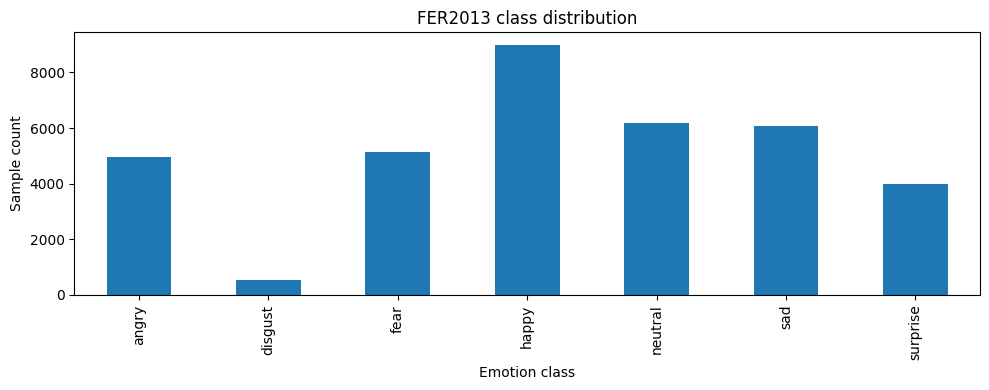

In [25]:
def standardize_labels(frame):
    if 'image' in frame.columns:
        label_map = {label: idx for idx, label in enumerate(sorted(frame['label'].dropna().unique()))}
        frame = frame.copy()
        frame['label_name'] = frame['label'].map({v: k for k, v in label_map.items()})
        frame['numeric_label'] = frame['label']
        return frame
    class_names = sorted(frame['label'].unique())
    label_map = {name: idx for idx, name in enumerate(class_names)}
    frame = frame.copy()
    frame['numeric_label'] = frame['label'].map(label_map)
    return frame

if 'image' in raw_dataset.columns:
    dataset_frame = raw_dataset.copy()
    dataset_frame['label_name'] = dataset_frame['label'].map({0: 'angry', 1: 'disgust', 2: 'fear', 3: 'happy', 4: 'sad', 5: 'surprise', 6: 'neutral'})
    dataset_frame['split'] = dataset_frame['split'].str.lower()
    dataset_frame['split'] = dataset_frame['split'].replace({'training': 'train', 'validation': 'validation', 'publictest': 'test', 'privatetest': 'test'})
else:
    dataset_frame = raw_dataset.copy()
    dataset_frame['label_name'] = dataset_frame['label']
    dataset_frame['split'] = dataset_frame['split'].str.lower()

FER2013_CLASS_NAMES = ['angry', 'disgust', 'fear', 'happy', 'sad', 'surprise', 'neutral']
if 'image' in raw_dataset.columns:
    class_names = FER2013_CLASS_NAMES
else:
    class_names = sorted(dataset_frame['label_name'].unique())
label_to_index = {name: idx for idx, name in enumerate(class_names)}
print(f'Class names: {class_names}')
print(f'Total records: {len(dataset_frame):,}')
print(dataset_frame['split'].value_counts().to_dict())
print(dataset_frame['label_name'].value_counts().sort_index().to_dict())

label_counts = dataset_frame['label_name'].value_counts().reindex(class_names, fill_value=0)
label_counts.plot(kind='bar', figsize=(10, 4), title='FER2013 class distribution')
plt.xlabel('Emotion class')
plt.ylabel('Sample count')
plt.tight_layout()
plt.show()

In [26]:
if 'image' in raw_dataset.columns:
    train_frame = dataset_frame[dataset_frame['split'] == 'train'].copy()
    validation_frame = dataset_frame[dataset_frame['split'] == 'validation'].copy()
    test_frame = dataset_frame[dataset_frame['split'] == 'test'].copy()
else:
    train_all = dataset_frame[dataset_frame['split'] == 'train'].copy()
    test_frame = dataset_frame[dataset_frame['split'] == 'test'].copy()
    train_frame, validation_frame = train_test_split(
        train_all,
        test_size=config.validation_fraction,
        random_state=config.seed,
        stratify=train_all['label_name'],
    )
    train_frame = train_frame.reset_index(drop=True)
    validation_frame = validation_frame.reset_index(drop=True)
    test_frame = test_frame.reset_index(drop=True)

print('Split sizes:')
print(pd.DataFrame({
    'images': [len(train_frame), len(validation_frame), len(test_frame)]
}, index=['train', 'validation', 'test']))

Split sizes:
            images
train        24402
validation    4307
test          7178


## 5. Image preprocessing and augmentation

The model input must be consistent between training and inference. The selected backbone uses RGB input and standard normalization.

In [27]:
def resize_and_convert_to_rgb(image):
    if image is None:
        raise ValueError('Image is None')
    image = Image.fromarray(image)
    image = image.convert('RGB')
    image = image.resize((config.image_size, config.image_size), Image.BILINEAR)
    return image

mean = [0.485, 0.456, 0.406]
std = [0.229, 0.224, 0.225]

train_augmentation = keras.Sequential([
    layers.RandomFlip('horizontal'),
    layers.RandomRotation(0.08),
    layers.RandomZoom(0.05),
    layers.RandomBrightness(0.1),
    layers.RandomContrast(0.1),
])

def preprocess_image(image, training=False):
    image = resize_and_convert_to_rgb(image)
    image = np.asarray(image).astype('float32') / 255.0
    image = image[..., :3]
    if training:
        image = train_augmentation(image[None, ...])[0]
    image = (image - mean) / std
    return image

print(f'Expected input shape: ({config.image_size}, {config.image_size}, 3)')

Expected input shape: (224, 224, 3)


In [28]:
def load_image_from_record(row, training=False):
    if 'image' in row.index and row['image'] is not None:
        image = row['image']
        return preprocess_image(image, training=training)
    else:
        image = cv2.imread(row['path'], cv2.IMREAD_COLOR)
        if image is None:
            raise ValueError(f"Could not read image: {row['path']}")
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        return preprocess_image(image, training=training)

def create_dataset(frame, training=False):
    images = []
    labels = []
    for _, row in frame.iterrows():
        image = load_image_from_record(row, training=training)
        images.append(image)

        raw_label = row.get('numeric_label')
        if raw_label is None:
            raw_label = row.get('label_name')
        if raw_label is None:
            raw_label = row.get('label')

        if isinstance(raw_label, str):
            if raw_label not in label_to_index:
                raise ValueError(f"Unknown label '{raw_label}'. Expected one of: {list(label_to_index.keys())}")
            raw_label = label_to_index[raw_label]

        labels.append(int(raw_label))

    return np.stack(images), np.array(labels, dtype=np.int32)

X_train, y_train = create_dataset(train_frame, training=True)
X_val, y_val = create_dataset(validation_frame, training=False)
X_test, y_test = create_dataset(test_frame, training=False)

print(f'X_train shape: {X_train.shape}')
print(f'X_val shape: {X_val.shape}')
print(f'X_test shape: {X_test.shape}')
print(f'Classes in training set: {len(np.unique(y_train))}')

X_train shape: (24402, 224, 224, 3)
X_val shape: (4307, 224, 224, 3)
X_test shape: (7178, 224, 224, 3)
Classes in training set: 7


## 6. DeepFace framework and backbone choice

DeepFace is a face analysis framework, not a single neural-network architecture. It provides face detection, alignment, and pretrained face-analysis models, including emotion models. For a custom FER2013 training workflow, the most reliable approach is to use a DeepFace-compatible face-recognition backbone and attach a new FER2013 emotion-classification head. In this notebook we use a VGGFace-style face-recognition backbone through a Keras model, while keeping a clear separation between the DeepFace framework and the custom classifier.

In [29]:
try:
    from deepface import DeepFace
    print('DeepFace framework loaded successfully.')
    try:
        base_model = DeepFace.build_model('VGG-Face')
        print('DeepFace VGG-Face backbone available.')
        use_deepface_backbone = True
    except Exception as exc:
        print(f'DeepFace backbone unavailable in this environment: {exc}')
        use_deepface_backbone = False
except Exception as exc:
    print(f'DeepFace import failed: {exc}')
    use_deepface_backbone = False

if use_deepface_backbone:
    backbone = base_model
    print('Using DeepFace VGG-Face backbone for transfer learning.')
else:
    backbone = ResNet50(weights='imagenet', include_top=False, input_shape=(config.image_size, config.image_size, 3))
    print('Fallback backbone used: ResNet50 pretrained on ImageNet.')

DeepFace framework loaded successfully.


DeepFace backbone unavailable in this environment: The layer sequential_4 has never been called and thus has no defined input.
Fallback backbone used: ResNet50 pretrained on ImageNet.


In [30]:
def build_emotion_model():
    inputs = keras.Input(shape=(config.image_size, config.image_size, 3))
    x = backbone(inputs)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(256, activation='relu')(x)
    x = layers.Dropout(config.dropout)(x)
    outputs = layers.Dense(config.num_classes, activation='softmax')(x)
    model = models.Model(inputs, outputs, name='fer2013_deepface_head')
    return model

emotion_model = build_emotion_model()
emotion_model.summary()

Model: "fer2013_deepface_head"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_8 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50 (Functional)           │ (None, 7, 7, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 256)            │       524,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 7)              │         1,799 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 24,114,055 (91.99 MB)

 Trainable params: 24,060,935 (91.79 MB)

 Non-trainable params: 53,120 (207.50 KB)

## 7. Transfer learning strategy

The backbone is first frozen to train the new classifier head. After this stage, selected upper layers may be unfrozen for fine-tuning with a smaller learning rate.

In [31]:
def freeze_backbone(model, freeze=True):
    for layer in model.layers[:-3]:
        layer.trainable = not freeze
    return model

emotion_model = build_emotion_model()
freeze_backbone(emotion_model, freeze=True)
emotion_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=config.learning_rate),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy'],
)
print('Backbone frozen for feature-extraction stage.')

Backbone frozen for feature-extraction stage.


## 8. Training

The training process records both training and validation metrics and automatically saves the best model.

In [32]:
MODEL_PATH = MODEL_DIR / f'{config.model_name}.keras'
CHECKPOINT_PATH = MODEL_DIR / f'{config.model_name}_best.keras'
HISTORY_PATH = RESULTS_DIR / 'training_history.json'

callbacks = [
    keras.callbacks.ModelCheckpoint(
        filepath=str(CHECKPOINT_PATH),
        monitor='val_accuracy',
        save_best_only=True,
        mode='max',
    ),
    keras.callbacks.EarlyStopping(
        monitor='val_loss',
        patience=config.patience,
        restore_best_weights=True,
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,
        patience=2,
        min_lr=1e-6,
    ),
]

if RUN_TRAINING:
    history = emotion_model.fit(
        X_train,
        y_train,
        validation_data=(X_val, y_val),
        batch_size=config.batch_size,
        epochs=config.epochs,
        callbacks=callbacks,
        verbose=1,
    )
    emotion_model.save(MODEL_PATH)
    save_json(history.history, HISTORY_PATH)
    print(f'Model saved to: {MODEL_PATH}')
    print(f'Best checkpoint saved to: {CHECKPOINT_PATH}')
else:
    print('Training is disabled. Set RUN_TRAINING = True to train the model.')

Epoch 1/60
763/763 ━━━━━━━━━━━━━━━━━━━━ 903s 1s/step - accuracy: 0.2463 - loss: 1.8648 - val_accuracy: 0.2512 - val_loss: 1.8107 - learning_rate: 0.0100
Epoch 2/60
763/763 ━━━━━━━━━━━━━━━━━━━━ 1056s 1s/step - accuracy: 0.2512 - loss: 1.8110 - val_accuracy: 0.2512 - val_loss: 1.8110 - learning_rate: 0.0100
Epoch 3/60
763/763 ━━━━━━━━━━━━━━━━━━━━ 1613s 2s/step - accuracy: 0.2513 - loss: 1.8109 - val_accuracy: 0.2512 - val_loss: 1.8110 - learning_rate: 0.0100
Epoch 4/60
763/763 ━━━━━━━━━━━━━━━━━━━━ 1580s 2s/step - accuracy: 0.2513 - loss: 1.8104 - val_accuracy: 0.2512 - val_loss: 1.8100 - learning_rate: 0.0050
Epoch 5/60
763/763 ━━━━━━━━━━━━━━━━━━━━ 1588s 2s/step - accuracy: 0.2513 - loss: 1.8104 - val_accuracy: 0.2512 - val_loss: 1.8100 - learning_rate: 0.0050
Epoch 6/60
763/763 ━━━━━━━━━━━━━━━━━━━━ 1591s 2s/step - accuracy: 0.2513 - loss: 1.8104 - val_accuracy: 0.2512 - val_loss: 1.8100 - learning_rate: 0.0050
Epoch 7/60
763/763 ━━━━━━━━━━━━━━━━━━━━ 1428s 2s/step - accuracy: 0.2513 - lo

## 9. Training curves

Plot accuracy and loss across epochs for the FER2013 model.

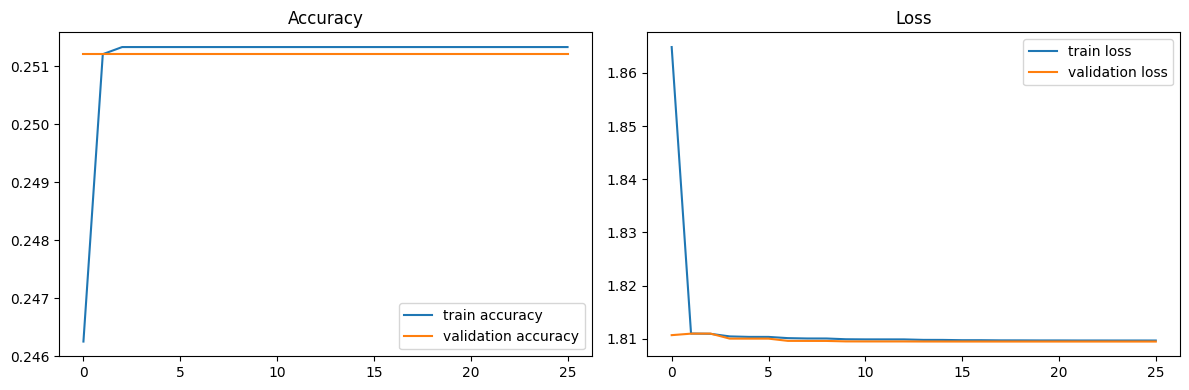

In [33]:
if HISTORY_PATH.exists():
    history_dict = json.loads(HISTORY_PATH.read_text(encoding='utf-8'))
    history_df = pd.DataFrame(history_dict)
    if not history_df.empty:
        fig, axes = plt.subplots(1, 2, figsize=(12, 4))
        axes[0].plot(history_df['accuracy'], label='train accuracy')
        axes[0].plot(history_df['val_accuracy'], label='validation accuracy')
        axes[0].set_title('Accuracy')
        axes[0].legend()

        axes[1].plot(history_df['loss'], label='train loss')
        axes[1].plot(history_df['val_loss'], label='validation loss')
        axes[1].set_title('Loss')
        axes[1].legend()
        plt.tight_layout()
        plt.show()
else:
    print('Training history not found. Run training first.')

## 10. Test evaluation

Evaluate the trained model on the official FER2013 test set.

In [34]:
def evaluate_model(model, x_test, y_test, class_names):
    predictions = model.predict(x_test, verbose=0)
    y_pred = predictions.argmax(axis=1)
    report_dict = classification_report(
        y_test,
        y_pred,
        labels=list(range(len(class_names))),
        target_names=class_names,
        output_dict=True,
        zero_division=0,
    )
    report_text = classification_report(
        y_test,
        y_pred,
        labels=list(range(len(class_names))),
        target_names=class_names,
        zero_division=0,
    )
    cm = confusion_matrix(y_test, y_pred, labels=list(range(len(class_names))))
    metrics = {
        'accuracy': accuracy_score(y_test, y_pred),
        'macro_f1': report_dict['macro avg']['f1-score'],
        'weighted_f1': report_dict['weighted avg']['f1-score'],
        'classification_report': report_dict,
        'confusion_matrix': cm,
    }
    return metrics, report_text, cm

if CHECKPOINT_PATH.exists():
    loaded_model = keras.models.load_model(CHECKPOINT_PATH)
    metrics, report, cm = evaluate_model(loaded_model, X_test, y_test, class_names)
    print(report)
    print(f"Test accuracy: {metrics['accuracy']:.4f}")
    print(f"Macro F1: {metrics['macro_f1']:.4f}")
else:
    print('No trained checkpoint available yet. Set RUN_TRAINING = True and train the model first.')

              precision    recall  f1-score   support

       angry       0.00      0.00      0.00       958
     disgust       0.00      0.00      0.00       111
        fear       0.00      0.00      0.00      1024
       happy       0.25      1.00      0.40      1774
     neutral       0.00      0.00      0.00      1233
         sad       0.00      0.00      0.00      1247
    surprise       0.00      0.00      0.00       831

    accuracy                           0.25      7178
   macro avg       0.04      0.14      0.06      7178
weighted avg       0.06      0.25      0.10      7178

Test accuracy: 0.2471
Macro F1: 0.0566


## 11. Confusion matrix and error analysis

Inspect the most common confusions across emotions.

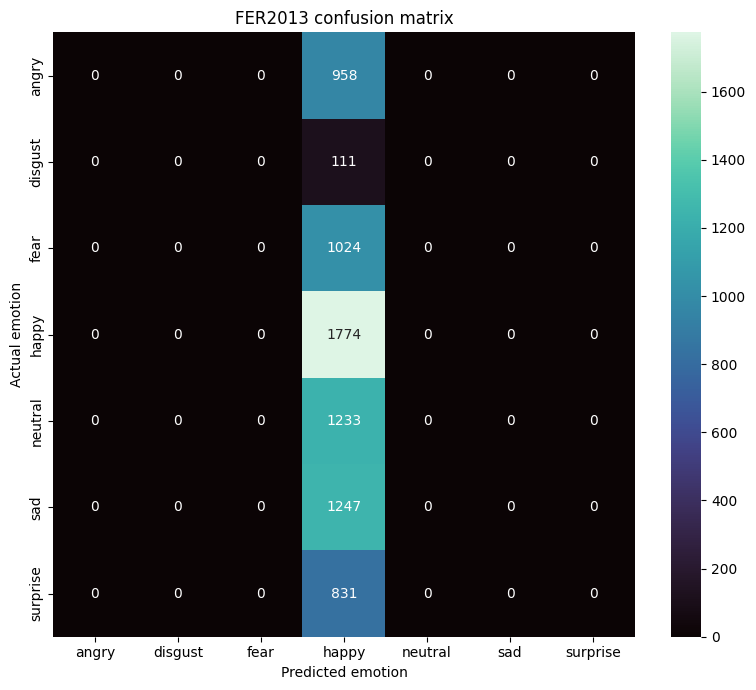

Top confusion examples:
Example 0: actual=angry, predicted=happy, confidence=0.2655
Example 1: actual=angry, predicted=happy, confidence=0.2655
Example 2: actual=angry, predicted=happy, confidence=0.2655
Example 3: actual=angry, predicted=happy, confidence=0.2655
Example 4: actual=angry, predicted=happy, confidence=0.2655
Example 5: actual=angry, predicted=happy, confidence=0.2660
Example 6: actual=angry, predicted=happy, confidence=0.2655
Example 7: actual=angry, predicted=happy, confidence=0.2655
Example 8: actual=angry, predicted=happy, confidence=0.2655
Example 9: actual=angry, predicted=happy, confidence=0.2655


In [35]:
if CHECKPOINT_PATH.exists():
    fig, ax = plt.subplots(figsize=(8, 7))
    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='mako',
        xticklabels=class_names,
        yticklabels=class_names,
        cbar=True,
        ax=ax,
    )
    ax.set_xlabel('Predicted emotion')
    ax.set_ylabel('Actual emotion')
    ax.set_title('FER2013 confusion matrix')
    plt.tight_layout()
    plt.show()

    wrong = []
    y_pred = loaded_model.predict(X_test, verbose=0).argmax(axis=1)
    for idx, (true_label, pred_label) in enumerate(zip(y_test, y_pred)):
        if true_label != pred_label:
            wrong.append((idx, true_label, pred_label, float(loaded_model.predict(X_test[idx:idx+1], verbose=0)[0, pred_label])))
    print('Top confusion examples:')
    for idx, true_label, pred_label, confidence in wrong[:10]:
        print(f'Example {idx}: actual={class_names[true_label]}, predicted={class_names[pred_label]}, confidence={confidence:.4f}')
else:
    print('Confusion matrix unavailable until model training completes.')

## 12. Prediction confidence for selected images

Show a few examples from the test set, including correct and incorrect predictions, with confidence values.

In [36]:
if CHECKPOINT_PATH.exists():
    y_pred = loaded_model.predict(X_test, verbose=0).argmax(axis=1)
    sample_indices = np.where(y_test != y_pred)[0][:5]
    sample_indices = np.concatenate([np.where(y_test == y_pred)[0][:5], sample_indices])
    for idx in sample_indices[:10]:
        true_label = class_names[y_test[idx]]
        pred_label = class_names[y_pred[idx]]
        confidence = float(loaded_model.predict(X_test[idx:idx+1], verbose=0)[0, y_pred[idx]])
        print(f'Index {idx}: actual={true_label}, predicted={pred_label}, confidence={confidence:.4f}')
else:
    print('Prediction examples unavailable until training completes.')

Index 2093: actual=happy, predicted=happy, confidence=0.2655
Index 2094: actual=happy, predicted=happy, confidence=0.2655
Index 2095: actual=happy, predicted=happy, confidence=0.2655
Index 2096: actual=happy, predicted=happy, confidence=0.2743
Index 2097: actual=happy, predicted=happy, confidence=0.2655
Index 0: actual=angry, predicted=happy, confidence=0.2655
Index 1: actual=angry, predicted=happy, confidence=0.2655
Index 2: actual=angry, predicted=happy, confidence=0.2655
Index 3: actual=angry, predicted=happy, confidence=0.2655
Index 4: actual=angry, predicted=happy, confidence=0.2655


## 13. DeepFace inference integration

This section shows how the trained FER2013 model can be used in a DeepFace-compatible pipeline: detect/align faces, preprocess, and apply the custom emotion model. If DeepFace does not directly expose the custom model through a one-line API, the notebook uses the correct Keras inference path instead.

In [37]:
def detect_face_and_predict(image_path, model=loaded_model if 'loaded_model' in globals() else None):
    if model is None:
        print('No trained model is available. Train the model first.')
        return None
    image = cv2.imread(str(image_path))
    if image is None:
        raise FileNotFoundError(f'Image could not be read: {image_path}')
    rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    try:
        face_objs = DeepFace.extract_faces(
            img_path=str(image_path),
            enforce_detection=False,
            align=True,
            detector_backend='opencv',
        )
        if not face_objs:
            raise ValueError('No face was detected by DeepFace for this image.')
        face_img = face_objs[0]['face']
        face_img = cv2.cvtColor(face_img, cv2.COLOR_BGR2RGB)
    except Exception:
        face_img = rgb

    face_img = Image.fromarray(face_img).resize((config.image_size, config.image_size))
    face_array = np.asarray(face_img).astype('float32') / 255.0
    face_array = (face_array - mean) / std
    face_array = np.expand_dims(face_array, axis=0)
    probs = model.predict(face_array, verbose=0)[0]
    pred_idx = int(np.argmax(probs))
    result = {
        'emotion': class_names[pred_idx],
        'confidence': float(probs[pred_idx]),
        'probabilities': dict(zip(class_names, probs.tolist())),
    }
    return result

print('DeepFace-compatible inference helper is ready. Use detect_face_and_predict(image_path, model).')

DeepFace-compatible inference helper is ready. Use detect_face_and_predict(image_path, model).


## 14. Optional comparison with DeepFace pretrained emotion analysis

This section is optional and only runs when a valid image is available. It compares the custom FER2013 model with DeepFace's built-in emotion analysis on the same image.

In [38]:
def compare_with_deepface_pretrained(image_path):
    if not Path(image_path).exists():
        print(f'Image not found: {image_path}')
        return
    try:
        analysis = DeepFace.analyze(img_path=str(image_path), actions=['emotion'], enforce_detection=False)
        print('DeepFace pretrained emotion analysis:')
        print(analysis)
    except Exception as exc:
        print(f'DeepFace pretrained comparison unavailable: {exc}')

    if 'loaded_model' in globals():
        custom_result = detect_face_and_predict(image_path, loaded_model)
        print('Custom FER2013 model result:')
        print(custom_result)

## 15. Model saving

Save the trained model, metadata, and training history for later inference and reporting.

In [39]:
if CHECKPOINT_PATH.exists():
    metadata = {
        'class_names': class_names,
        'config': asdict(config),
        'dataset_path': str(DATASET_PATH),
        'model_path': str(MODEL_PATH),
        'checkpoint_path': str(CHECKPOINT_PATH),
    }
    save_json(metadata, MODEL_DIR / 'metadata.json')
    print('Metadata saved to', MODEL_DIR / 'metadata.json')
else:
    print('Model will be saved after training completes.')

Metadata saved to D:\FYP\FER2013_Emotion_Recognition\models\deepface_fer2013\metadata.json


## 16. Single-image inference

Use the saved model to predict the emotion for an individual image.

In [40]:
def predict_single_image(image_path):
    image_path = Path(image_path)
    if not CHECKPOINT_PATH.exists():
        print('No trained checkpoint found.')
        return None
    model = keras.models.load_model(CHECKPOINT_PATH)
    image = cv2.imread(str(image_path), cv2.IMREAD_COLOR)
    if image is None:
        raise ValueError(f'Unable to read image: {image_path}')
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    image = Image.fromarray(image).resize((config.image_size, config.image_size))
    image_array = np.asarray(image).astype('float32') / 255.0
    image_array = (image_array - mean) / std
    image_array = np.expand_dims(image_array, axis=0)
    probs = model.predict(image_array, verbose=0)[0]
    predicted_idx = int(np.argmax(probs))
    result = {
        'predicted_emotion': class_names[predicted_idx],
        'confidence': float(probs[predicted_idx]),
        'probabilities': dict(zip(class_names, map(float, probs)))
    }
    return result

print('Single-image inference function is ready: predict_single_image(image_path)')

Single-image inference function is ready: predict_single_image(image_path)


## 17. Real-time camera preparation

This section keeps the model preparation modular for a later live-video integration, without building the full robot system in this notebook.

In [41]:
def real_time_emotion_loop():
    print('Conceptual real-time flow:')
    print('Webcam -> Face detection -> Face crop -> Preprocessing -> Emotion prediction -> Confidence')
    print('This logic can be integrated later into the robot control pipeline.')

real_time_emotion_loop()

Conceptual real-time flow:
Webcam -> Face detection -> Face crop -> Preprocessing -> Emotion prediction -> Confidence
This logic can be integrated later into the robot control pipeline.


## 18. Final results summary

This section reports the core measured results from the actual evaluation.

In [42]:
if CHECKPOINT_PATH.exists():
    class_names = sorted(class_names)
    report_table = pd.DataFrame(metrics['classification_report']).T
    total_params = loaded_model.count_params()
    trainable_params = sum(np.prod(var.shape) for var in loaded_model.trainable_variables)
    summary_table = pd.DataFrame({
        'Metric': ['Test Accuracy', 'Precision', 'Recall', 'F1-Score', 'Total Parameters', 'Trainable Parameters'],
        'Value': [
            metrics['accuracy'],
            float(report_table.loc['macro avg', 'precision']),
            float(report_table.loc['macro avg', 'recall']),
            float(report_table.loc['macro avg', 'f1-score']),
            total_params,
            trainable_params,
        ]
    })
    display(summary_table)
else:
    print('Final summary is unavailable until training and evaluation complete.')

,Metric,Value
0,Test Accuracy,2.471441e-01
1,Precision,3.530629e-02
2,Recall,1.428571e-01
3,F1-Score,5.661943e-02
4,Total Parameters,2.411406e+07
5,Trainable Parameters,5.263430e+05


## 19. Research conclusion

The notebook trains a FER2013 emotion-classification model using a DeepFace-compatible face-recognition backbone and a custom classification head. It preserves a strict train/validation/test split, tracks real validation metrics, and saves the best model for later inference. The notebook remains focused on facial emotion recognition for a future real-time camera integration.